# **Studi Kasus: Evaluasi Usability dan Visualisasi Data Interaktif Menggunakan Google Colab**

Sebuah tim pengembang aplikasi pendidikan ingin membuat dashboard untuk menampilkan hasil belajar mahasiswa agar dosen dapat memahami perkembangan akademik secara lebih mudah. Namun, dashboard yang tersedia masih memiliki beberapa permasalahan, seperti terlalu banyak elemen visual, penggunaan warna yang kurang konsisten, informasi penting yang sulit ditemukan, dan tata letak yang membingungkan pengguna. Kondisi tersebut dapat meningkatkan cognitive load atau beban kognitif, sehingga pengguna membutuhkan lebih banyak waktu untuk memahami informasi yang disajikan. Untuk mengatasi masalah tersebut, mahasiswa diminta melakukan simulasi penerapan prinsip Interaksi Manusia dan Komputer (IMK) dengan menggunakan Python melalui Google Colab untuk mengolah data hasil belajar, membuat visualisasi yang informatif, dan mengevaluasi kemudahan pengguna dalam memahami dashboard.

Dalam studi kasus ini, mahasiswa menggunakan dataset sintetis yang berisi nilai mahasiswa pada beberapa mata kuliah, seperti Pemrograman, Basis Data, dan Interaksi Manusia dan Komputer. Data kemudian diolah menggunakan Pandas dan divisualisasikan dengan Matplotlib. Dashboard dirancang dengan memperhatikan prinsip User-Centered Design, yaitu menempatkan kebutuhan pengguna sebagai dasar perancangan, menerapkan prinsip Gestalt untuk mengelompokkan informasi yang saling berkaitan, serta memperhatikan data-ink ratio agar elemen visual yang tidak diperlukan dapat diminimalkan. Selain itu, mahasiswa melakukan simulasi evaluasi usability melalui beberapa pertanyaan yang mengukur kemudahan menemukan informasi, memahami grafik, dan mengenali mahasiswa yang membutuhkan pendampingan akademik. Hasil evaluasi digunakan untuk mengidentifikasi bagian antarmuka yang perlu diperbaiki. Melalui studi kasus ini, mahasiswa diharapkan memahami bahwa antarmuka yang baik tidak hanya menarik secara visual, tetapi juga mudah dipahami, efisien digunakan, dan sesuai dengan kebutuhan serta kemampuan penggunanya.

=== DATA AKADEMIK MAHASISWA ===


,mahasiswa,pemrograman,basis_data,imk,rata_rata,kategori
0,Mahasiswa A,85,80,88,84.33,Baik
1,Mahasiswa B,60,65,70,65.00,Cukup
2,Mahasiswa C,78,75,82,78.33,Baik
3,Mahasiswa D,45,50,48,47.67,Perlu Pendampingan
4,Mahasiswa E,90,92,95,92.33,Sangat Baik
5,Mahasiswa F,55,60,58,57.67,Perlu Pendampingan
6,Mahasiswa G,72,70,76,72.67,Cukup
7,Mahasiswa H,88,85,90,87.67,Sangat Baik
8,Mahasiswa I,50,55,52,52.33,Perlu Pendampingan
9,Mahasiswa J,80,78,84,80.67,Baik



=== DASHBOARD: PEMROGRAMAN ===
Jumlah mahasiswa: 10
Rata-rata kelas: 70.3
Nilai tertinggi: 90
Nilai terendah: 45


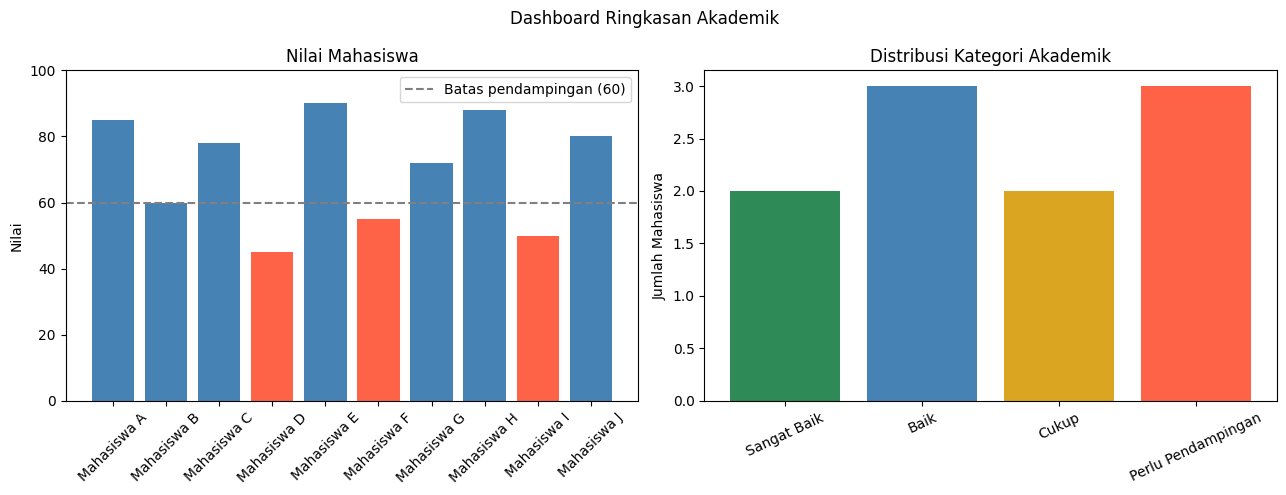


=== MAHASISWA YANG PERLU DIPERHATIKAN ===


,mahasiswa,pemrograman,basis_data,imk,rata_rata
3,Mahasiswa D,45,50,48,47.67
5,Mahasiswa F,55,60,58,57.67
8,Mahasiswa I,50,55,52,52.33



=== HASIL SIMULASI EVALUASI USABILITY ===


,aspek,skor
0,Kemudahan menemukan informasi,4
1,Kejelasan grafik,4
2,Kemudahan membaca teks,3
3,Konsistensi warna,5
4,Kemudahan memahami dashboard,4


Rata-rata skor usability: 4.00/5
Interpretasi: antarmuka dinilai cukup mudah digunakan.

Catatan: data akademik dan skor usability merupakan data simulasi, bukan hasil pengujian pengguna nyata.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Membuat dataset sintetis mahasiswa
data = {
    "mahasiswa": [
        "Mahasiswa A", "Mahasiswa B", "Mahasiswa C",
        "Mahasiswa D", "Mahasiswa E", "Mahasiswa F",
        "Mahasiswa G", "Mahasiswa H", "Mahasiswa I",
        "Mahasiswa J"
    ],
    "pemrograman": [85, 60, 78, 45, 90, 55, 72, 88, 50, 80],
    "basis_data": [80, 65, 75, 50, 92, 60, 70, 85, 55, 78],
    "imk": [88, 70, 82, 48, 95, 58, 76, 90, 52, 84]
}

df = pd.DataFrame(data)
mata_kuliah = ["pemrograman", "basis_data", "imk"]

# 2. Menghitung rata-rata nilai mahasiswa
df["rata_rata"] = df[mata_kuliah].mean(axis=1).round(2)

def kategori_nilai(nilai):
    if nilai >= 85:
        return "Sangat Baik"
    elif nilai >= 75:
        return "Baik"
    elif nilai >= 60:
        return "Cukup"
    return "Perlu Pendampingan"

df["kategori"] = df["rata_rata"].apply(kategori_nilai)

print("=== DATA AKADEMIK MAHASISWA ===")
display(df)

# 3. Memilih mata kuliah untuk analisis
# Ganti pilihan menjadi "pemrograman", "basis_data",
# atau "imk" untuk melihat mata kuliah lainnya.
pilihan = "pemrograman"

if pilihan not in mata_kuliah:
    raise ValueError("Pilihan mata kuliah tidak tersedia.")

print(f"\n=== DASHBOARD: {pilihan.upper()} ===")
print("Jumlah mahasiswa:", len(df))
print("Rata-rata kelas:", round(df[pilihan].mean(), 2))
print("Nilai tertinggi:", df[pilihan].max())
print("Nilai terendah:", df[pilihan].min())

# 4. Visualisasi data dengan layout sederhana
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik pertama: perbandingan nilai mahasiswa
warna_batang = [
    "tomato" if nilai < 60 else "steelblue"
    for nilai in df[pilihan]
]

axes[0].bar(
    df["mahasiswa"],
    df[pilihan],
    color=warna_batang
)
axes[0].axhline(
    60, linestyle="--", color="gray",
    label="Batas pendampingan (60)"
)
axes[0].set_title("Nilai Mahasiswa")
axes[0].set_ylabel("Nilai")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

# Grafik kedua: distribusi kategori akademik
urutan = [
    "Sangat Baik", "Baik", "Cukup",
    "Perlu Pendampingan"
]
distribusi = (
    df["kategori"]
    .value_counts()
    .reindex(urutan, fill_value=0)
)

axes[1].bar(
    distribusi.index,
    distribusi.values,
    color=["seagreen", "steelblue", "goldenrod", "tomato"]
)
axes[1].set_title("Distribusi Kategori Akademik")
axes[1].set_ylabel("Jumlah Mahasiswa")
axes[1].tick_params(axis="x", rotation=25)

plt.suptitle("Dashboard Ringkasan Akademik")
plt.tight_layout()
plt.show()

print("\n=== MAHASISWA YANG PERLU DIPERHATIKAN ===")

pendampingan = df[df["rata_rata"] < 60][
    ["mahasiswa", *mata_kuliah, "rata_rata"]
]

if pendampingan.empty:
    print("Tidak ada mahasiswa dengan rata-rata di bawah 60.")
else:
    display(pendampingan)


evaluasi = pd.DataFrame({
    "aspek": [
        "Kemudahan menemukan informasi",
        "Kejelasan grafik",
        "Kemudahan membaca teks",
        "Konsistensi warna",
        "Kemudahan memahami dashboard"
    ],
    "skor": [4, 4, 3, 5, 4]
})

print("\n=== HASIL SIMULASI EVALUASI USABILITY ===")
display(evaluasi)

rata_usability = evaluasi["skor"].mean()
print(f"Rata-rata skor usability: {rata_usability:.2f}/5")

if rata_usability >= 4:
    print("Interpretasi: antarmuka dinilai cukup mudah digunakan.")
elif rata_usability >= 3:
    print("Interpretasi: antarmuka cukup dipahami, tetapi perlu perbaikan.")
else:
    print("Interpretasi: antarmuka membutuhkan evaluasi dan perbaikan.")

print(
    "\nCatatan: data akademik dan skor usability merupakan "
    "data simulasi, bukan hasil pengujian pengguna nyata."
)


Berdasarkan studi kasus evaluasi usability dan visualisasi data akademik menggunakan Google Colab, dapat disimpulkan bahwa prinsip Interaksi Manusia dan Komputer berperan penting dalam menghasilkan antarmuka yang mudah dipahami dan digunakan. Pengolahan data menggunakan Pandas dan visualisasi menggunakan Matplotlib membantu menyajikan informasi akademik secara lebih terstruktur sehingga pengguna dapat membandingkan nilai, memahami distribusi hasil belajar, dan mengidentifikasi mahasiswa yang membutuhkan perhatian lebih lanjut. Penerapan prinsip User-Centered Design, pengelompokan informasi berdasarkan prinsip Gestalt, serta pengurangan elemen visual yang tidak diperlukan dapat membantu mengurangi beban kognitif pengguna.

Studi kasus ini juga menunjukkan bahwa keberhasilan desain antarmuka tidak hanya ditentukan oleh tampilan visual, tetapi juga oleh kemampuan antarmuka dalam membantu pengguna menyelesaikan tugas secara efektif, efisien, dan nyaman. Oleh karena itu, proses desain perlu dilakukan secara iteratif melalui analisis kebutuhan, pembuatan prototipe, pengujian usability, dan perbaikan berdasarkan umpan balik pengguna. Hasil simulasi ini dapat menjadi dasar pembelajaran untuk mengembangkan dashboard yang lebih interaktif, mudah diakses, dan sesuai dengan kebutuhan pengguna. Namun, penilaian kualitas antarmuka yang sebenarnya tetap membutuhkan pengujian langsung dengan pengguna yang mewakili sasaran aplikasi.